# 05. Comms schedule

Which link the boat talks over, and when. Starlink matters for energy (~22 W while on, nb 06); Iridium and Globalstar are small.

1. **Starlink schedule:** when the terminal wakes and for how long. This is a boat setting, not part of the mission, and runs alongside the modes (nb 04).

The plan saved for the forecast (nb 12) is **every Starlink session** (scheduled, extra and deployment), in `data/mission/mission_starlink.csv`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

plt.rcParams.update({"figure.figsize": (14, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

df = pd.read_csv("../data/scout_telemetry_2025-07.csv", na_values="null")
df["t"] = pd.to_datetime(df["created_at"], format="ISO8601", utc=True)
df = df.sort_values("t").reset_index(drop=True)
df["P_load"] = df.voltage_battery1_v * df.current_battery2_a     # W, total load, both links
df["P_solar"] = df.voltage_battery3_v * df.current_battery3_a    # W, Starlink rows only

# Starlink sessions: same rule as nb 06 (Starlink messages < 2 min apart = one session)
direct = df[df.communication_mode == "direct"]
session_id = (direct.t.diff() > pd.Timedelta("2min")).cumsum()
sessions = direct.groupby(session_id).t.agg(start="min", end="max").reset_index(drop=True)
sessions["minutes"] = (sessions.end - sessions.start).dt.total_seconds() / 60

MODE_NAMES = {0: "MANUAL", 10: "AUTO", 16: "INITIALISING", 17: "mode 17"}
LINK_COLORS = {"direct": "#1f77b4", "imt": "#ff7f0e", "globalstar": "#2ca02c"}
STARLINK_W = 22                                                  # nb 06
print(f"{len(sessions)} Starlink sessions, {sessions.start.min():%d %b %H:%M} to {sessions.end.max():%d %b %H:%M}")

def dist_m(lat1, lon1, lat2, lon2):
    """Great-circle distance in metres."""
    p1, p2 = np.radians(lat1), np.radians(lat2)
    a = np.sin((p2 - p1) / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(np.radians(np.asarray(lon2) - np.asarray(lon1)) / 2) ** 2
    return 2 * 6_371_000 * np.arcsin(np.sqrt(a))

MODE_COLORS = {0: "#9e9e9e", 10: "#2ca02c", 16: "#9467bd", 17: "#d62728"}   # same as nb 01 / nb 02
HOTEL_W = 10                                                     # nb 06

# Starlink on = inside a session (messages < 2 min apart) +- 30 s, same rule as nb 06
df["starlink"] = False
for s in sessions.itertuples():
    df.loc[df.t.between(s.start - pd.Timedelta("30s"), s.end + pd.Timedelta("30s")), "starlink"] = True
df["P_motor"] = df.P_load - HOTEL_W - STARLINK_W * df.starlink   # what's left of the load: roughly the thruster

159 Starlink sessions, 14 Jul 07:43 to 27 Jul 02:05


# 1. Starlink schedule

*(Moved here from nb 12.)*

Each Starlink session is a bar at its time of day, one row per day. Starlink always comes up at about **:47 past the hour**, so a session that starts between **:44 and :56** counts as **scheduled** (dark blue). Anything else is **extra** (light blue), most likely switched on by hand from shore.

The schedule has three phases (read off the plot, then checked in the table below):
- **Deployment, 14 Jul 07:43 to 15 Jul 20:00:** on for hours at a time, no schedule.
- **Every 2 h, 15 Jul 20:00 to 19 Jul 22:00:** at even UTC hours (00:47, 02:47, …).
- **Every 3 h, 19 Jul 22:00 to 27 Jul 02:05:** at 01:47, 04:47, 07:47, …, 22:47.

After 27 Jul 02:05 Starlink never comes back (last day, see nb 03). The small grey ticks mark each phase's scheduled slots, so a tick with no bar on it is a **missed slot**. Neither schedule includes 03:00, which is why there's never a Starlink row in that hour (nb 01).

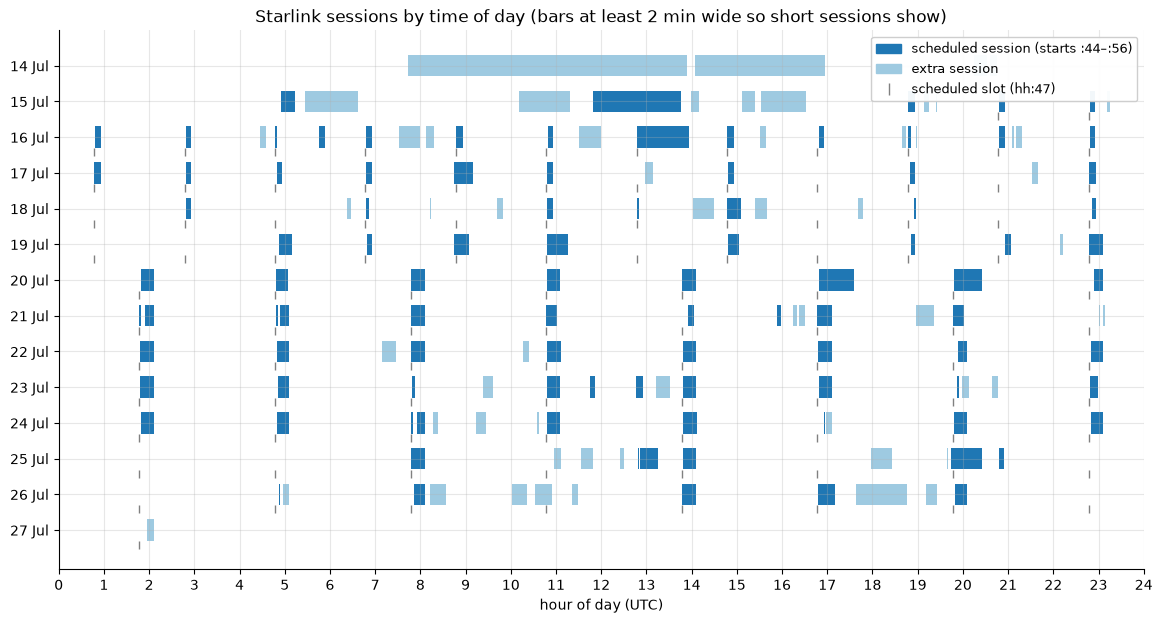

,sessions,scheduled,slots hit,median scheduled length (min),Starlink on (h per day),average Starlink power (W)
phase,,,,,,
deployment,14,3,NaN,18.1,10.5,9.6
every 2 h,57,38,37 / 49,7.7,2.4,2.2
every 3 h,88,58,48 / 58,16.3,2.9,2.6


In [2]:
PHASES = [   # name, start, end, scheduled UTC hours (None = no schedule)
    ("deployment", "2025-07-14 00:00", "2025-07-15 20:00", None),
    ("every 2 h",  "2025-07-15 20:00", "2025-07-19 22:00", list(range(0, 24, 2))),
    ("every 3 h",  "2025-07-19 22:00", "2025-07-27 02:30", [1, 4, 7, 10, 13, 16, 19, 22]),
    ("off",        "2025-07-27 02:30", "2025-07-31 00:00", None),
]
PHASES = [(n, pd.Timestamp(a, tz="UTC"), pd.Timestamp(b, tz="UTC"), h) for n, a, b, h in PHASES]
sessions["scheduled"] = sessions.start.dt.minute.between(44, 56)
sessions["phase"] = [next(n for n, a, b, _ in PHASES if a <= t < b) for t in sessions.start]

# scheduled slots (slot at hh:47) and whether a session started within :44-:56 of it
slots = pd.DataFrame([(n, s + pd.Timedelta("47min")) for n, a, b, hrs in PHASES if hrs
                      for s in pd.date_range(a, b, freq="1h", inclusive="left") if s.hour in hrs], columns=["phase", "t"])
slots["hit"] = [((sessions.start >= t - pd.Timedelta("3min")) & (sessions.start <= t + pd.Timedelta("9min"))).any() for t in slots.t]

days = pd.date_range("2025-07-14", "2025-07-27", tz="UTC")
fig, ax = plt.subplots(figsize=(14, 7))
for i, day in enumerate(days):
    for s in sessions[sessions.start.dt.floor("D") == day].itertuples():
        h0 = (s.start - day).total_seconds() / 3600
        ax.barh(i, max(s.minutes, 2) / 60, left=h0, height=0.6, color="#1f77b4" if s.scheduled else "#9ecae1", lw=0)
    sl = slots[slots.t.dt.floor("D") == day]
    ax.plot((sl.t - day).dt.total_seconds() / 3600, np.full(len(sl), i + 0.42), "|", ms=6, color="grey")
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
handles = [Patch(color="#1f77b4", label="scheduled session (starts :44–:56)"), Patch(color="#9ecae1", label="extra session"),
           Line2D([], [], marker="|", ls="", ms=8, color="grey", label="scheduled slot (hh:47)")]
ax.set_yticks(range(len(days)), [f"{d:%d %b}" for d in days]); ax.invert_yaxis()
ax.set_xlim(0, 24); ax.set_xticks(range(0, 25, 1))
ax.set_xlabel("hour of day (UTC)")
ax.set_title("Starlink sessions by time of day (bars at least 2 min wide so short sessions show)")
ax.legend(handles=handles, loc="upper right", fontsize=9, framealpha=0.95)
plt.show()

g = sessions.groupby("phase", sort=False)
span_h = {n: (min(b, sessions.end.max()) - max(a, sessions.start.min())).total_seconds() / 3600 for n, a, b, _ in PHASES if n != "off"}
table = pd.DataFrame({
    "sessions": g.size(),
    "scheduled": g.scheduled.sum(),
    "slots hit": slots.groupby("phase").hit.sum().astype(int).astype(str) + " / " + slots.groupby("phase").size().astype(str),
    "median scheduled length (min)": g.apply(lambda x: x[x.scheduled].minutes.median()),
    "Starlink on (h per day)": g.minutes.sum() / 60 / pd.Series(span_h) * 24,
})
table["average Starlink power (W)"] = table["Starlink on (h per day)"] / 24 * STARLINK_W
table.round(1)

### The predictable part, as the boat would have been given it

Drop the extra (hand-switched) sessions and the deployment day, and the schedule is just a table: from when, at which hours, for how long. Starlink wakes at **hh:47** and stays up for the median scheduled length of that phase.

In [3]:
STARLINK_SCHEDULE = []
for name, a, b, hrs in PHASES:
    if hrs is None:
        continue
    STARLINK_SCHEDULE.append({
        "from": a, "to": min(b, sessions.end.max()),
        "wake at (UTC)": ", ".join(f"{h:02d}:47" for h in hrs),
        "on for (min)": round(sessions[(sessions.phase == name) & sessions.scheduled].minutes.median()),
    })
STARLINK_SCHEDULE.append({"from": PHASES[-1][1], "to": pd.Timestamp("2025-07-31", tz="UTC"),
                          "wake at (UTC)": "never (off)", "on for (min)": 0})
STARLINK_SCHEDULE = pd.DataFrame(STARLINK_SCHEDULE)
STARLINK_SCHEDULE.style.format({"from": "{:%d %b %H:%M}", "to": "{:%d %b %H:%M}"})

,from,to,wake at (UTC),on for (min)
0,15 Jul 20:00,19 Jul 22:00,"00:47, 02:47, 04:47, 06:47, 08:47, 10:47, 12:47, 14:47, 16:47, 18:47, 20:47, 22:47",8
1,19 Jul 22:00,27 Jul 02:05,"01:47, 04:47, 07:47, 10:47, 13:47, 16:47, 19:47, 22:47",16
2,27 Jul 02:30,31 Jul 00:00,never (off),0


### Saved for the forecast: every session

The schedule above leaves out the extra sessions (switched on from shore) and gives the deployment phase only a duty cycle. For now the plan uses **all sessions**: each one is an on-window from its first to its last Starlink message, ± 30 s (the same rule as the `starlink` flag, nb 07).

`data/mission/mission_starlink.csv`: one row per session, `from`, `to` and `kind` (deployment / scheduled / extra). The readers (nb 07, 08, 13) turn it into the share of each minute that Starlink was on.

In [4]:
sl_out = pd.DataFrame({
    "from": sessions.start - pd.Timedelta("30s"),
    "to": sessions.end + pd.Timedelta("30s"),
    "kind": np.where(sessions.phase == "deployment", "deployment", np.where(sessions.scheduled, "scheduled", "extra")),
})
sl_out.to_csv("../data/mission/mission_starlink.csv", index=False)
print(f"{len(sl_out)} sessions saved to data/mission/mission_starlink.csv")
sl_out.assign(hours=(sl_out.to - sl_out["from"]).dt.total_seconds() / 3600).groupby("kind").hours.agg(sessions="size", hours="sum").round(1)

159 sessions saved to data/mission/mission_starlink.csv


,sessions,hours
kind,,
deployment,14,16.0
extra,49,10.1
scheduled,96,22.5
